# MedSAM covariance + SPDNet vs GAP + Linear: results walkthrough

This notebook **only reads saved results** (`results/`, `splits/`, `checks/outputs/`).
It needs numpy, pandas and matplotlib, no GPU, and runs in about two minutes.
The experiments themselves are run with the scripts in `src/` (see `README.md`).

1. Experimental settings
2. Data splits
3. Main results (2 datasets × 3 heads)
4. Is the difference real? Paired bootstrap
5. Where do the methods differ? Per-class recall and confusion matrices
6. Cost
7. Why ReEig matters: MedSAM covariances have rank 255
8. Findings → answers to the four questions

In [1]:
import json, os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.insert(0, os.path.join(REPO, 'src'))
import compare, eval_report

RES = os.path.join(REPO, 'results')
EXPERIMENTS = {  # results folder: (dataset, head)
    'derma_spdnet': ('DermaMNIST', 'Covariance + SPDNet'),
    'derma_gap_zscore': ('DermaMNIST', 'GAP + z-score + Linear'),
    'derma_gap': ('DermaMNIST', 'GAP + Linear (no scaling, ablation)'),
    'kvasir_spdnet': ('Kvasir-v2', 'Covariance + SPDNet'),
    'kvasir_gap_zscore': ('Kvasir-v2', 'GAP + z-score + Linear'),
    'kvasir_gap': ('Kvasir-v2', 'GAP + Linear (no scaling, ablation)'),
}
SPD, GAP = '#eb6834', '#2a78d6'   # validated categorical pair (orange = SPDNet, blue = GAP)
pd.set_option('display.precision', 1)

## 1. Experimental settings

| | Setting |
|---|---|
| Encoder | MedSAM ViT-B (`medsam_vit_b.pth`), **frozen**, image encoder only; output (256, 64, 64) |
| Preprocessing | official `transform_demo`: resize to 1024² (bicubic), per-channel min-max |
| Descriptors | **covariance** 256×256 of the 4,096 patch vectors (official `cov_descr`) and **GAP** 256 = their mean; both from the same forward pass |
| Heads | SPDNet: BiMap 256→128→64→32, ReEig (1e-4), LogEig, Linear · GAP: optional z-score (train statistics only), Linear |
| Training (shared, official `fit_spdnet`) | class-weighted cross-entropy; Adam lr 1e-3 (Euclidean) + Riemannian SGD on the Stiefel manifold (BiMap); batch 32, max 250 epochs, early stopping on val balanced accuracy (patience 15), checkpoint on min val loss; **5 repeats, seeds 1–5** |
| Metrics | balanced accuracy (main), macro F1, macro AUROC; mean ± sample std over 5 repeats, on the **full** test set |
| Statistics | paired bootstrap over test images (10,000 resamples) for the difference of the 5-run means |

The z-score baseline was fixed as the main GAP baseline **before** seeing any result (MedSAM GAP values are small and their per-dimension spread differs by ~1,900×); the unscaled version is an ablation.

## 2. Data splits

In [2]:
derma = pd.DataFrame({'train': [7007], 'val': [1003], 'test': [2005]}, index=['DermaMNIST (official split, 7 classes, 64×64)'])
info = json.load(open(os.path.join(REPO, 'splits', 'kvasir_v2_split_info.json')))
kv = pd.DataFrame(info['per_class']).T
kv.loc['total'] = kv.sum()
print('Kvasir-v2 split: seed', info['seed'], '| ratios', info['ratios'], '| dHash duplicate threshold', info['dup_threshold_dhash256'])
print('dropped (same file in two classes):', info['dropped_label_conflict'])
print('split CSV sha256:', info['sha256_split_csv'])
display(derma)
display(kv)

Kvasir-v2 split: seed 42 | ratios {'train': 0.7, 'test': 0.2, 'val': 0.1} | dHash duplicate threshold 20
dropped (same file in two classes): ['dyed-lifted-polyps/2164dff2-d611-4570-8c60-ce88f8b2f7f3.jpg', 'dyed-resection-margins/2164dff2-d611-4570-8c60-ce88f8b2f7f3.jpg']
split CSV sha256: 4b477c457e726bc7f201fe7fab04e6ec55c324e6941a1acc6791f9b3e679ad1f


,train,val,test
"DermaMNIST (official split, 7 classes, 64×64)",7007,1003,2005


,train,val,test
dyed-lifted-polyps,699,100,200
dyed-resection-margins,699,100,200
esophagitis,700,100,200
normal-cecum,700,100,200
normal-pylorus,700,100,200
normal-z-line,700,100,200
polyps,700,100,200
ulcerative-colitis,700,100,200
total,5598,800,1600


Kvasir-v2 has no official split and no patient IDs. `data_prep/` builds a fixed split in three steps:
an audit (SHA-1 per file, sizes per class), a near-duplicate search (256-bit dHash of the image centre),
and a grouped, stratified 70/10/20 split in which near-duplicates (distance ≤ 20) never cross splits.
Example pairs at each distance: `splits/near_dup_examples.png`.

## 3. Main results

In [3]:
rows = []
for name, (ds, head) in EXPERIMENTS.items():
    runs = pd.read_csv(os.path.join(RES, name, 'per_run.csv'), sep=';')
    fit = json.load(open(os.path.join(RES, name, 'fit_summary.json')))
    row = {'Dataset': ds, 'Head': head}
    for m in ('Balanced accuracy', 'Macro F1', 'Macro AUROC'):
        row[m] = f"{100 * runs[m].mean():.1f} ± {100 * runs[m].std(ddof=1):.1f}"
    row['Train time (5 runs, min)'] = fit['minutes']
    row['Trainable params'] = f"{fit['trainable_params']:,}"
    rows.append(row)
main = pd.DataFrame(rows).set_index(['Dataset', 'Head'])
main

Balanced accuracy    Macro F1  \
Dataset    Head                                                                
DermaMNIST Covariance + SPDNet                        54.4 ± 1.8  39.5 ± 1.4   
           GAP + z-score + Linear                     56.0 ± 0.8  39.4 ± 0.4   
           GAP + Linear (no scaling, ablation)        45.6 ± 0.4  29.8 ± 0.1   
Kvasir-v2  Covariance + SPDNet                        85.3 ± 0.8  85.2 ± 0.8   
           GAP + z-score + Linear                     84.8 ± 0.4  84.8 ± 0.4   
           GAP + Linear (no scaling, ablation)        75.0 ± 3.1  74.8 ± 3.3   

                                               Macro AUROC  \
Dataset    Head                                              
DermaMNIST Covariance + SPDNet                  88.6 ± 0.3   
           GAP + z-score + Linear               87.3 ± 0.3   
           GAP + Linear (no scaling, ablation)  81.8 ± 0.0   
Kvasir-v2  Covariance + SPDNet                  98.8 ± 0.1   
           GAP + z-score + Linear               98.7 ± 0.0   
           GAP + Linear (no scaling, ablation)  97.0 ± 0.7   

                                                Train time (5 runs, min)  \
Dataset    Head                                                            
DermaMNIST Covariance + SPDNet                                     176.0   
           GAP + z-score + Linear                                    4.9   
           GAP + Linear (no scaling, ablation)                      12.8   
Kvasir-v2  Covariance + SPDNet                                     131.2   
           GAP + z-score + Linear                                   11.1   
           GAP + Linear (no scaling, ablation)                      26.3   

                                               Trainable params  
Dataset    Head                                                  
DermaMNIST Covariance + SPDNet                           50,183  
           GAP + z-score + Linear                         1,799  
           GAP + Linear (no scaling, ablation)            1,799  
Kvasir-v2  Covariance + SPDNet                           51,208  
           GAP + z-score + Linear                         2,056  
           GAP + Linear (no scaling, ablation)            2,056

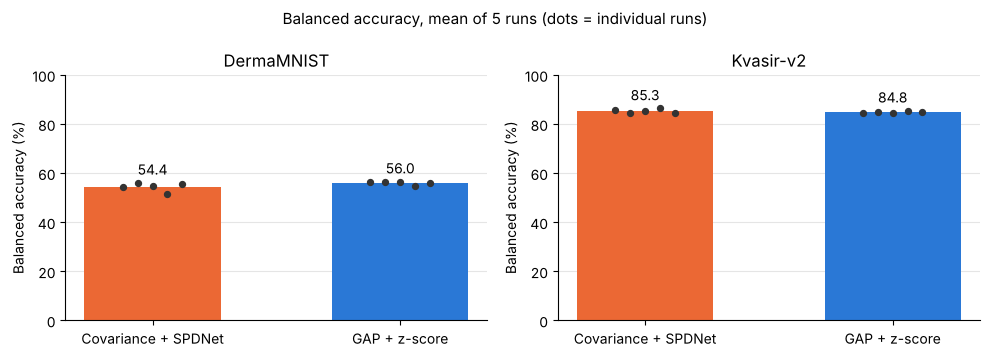

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=False)
for ax, ds in zip(axes, ('derma', 'kvasir')):
    names = [f'{ds}_spdnet', f'{ds}_gap_zscore']
    for x, (n, color) in enumerate(zip(names, (SPD, GAP))):
        ba = 100 * pd.read_csv(os.path.join(RES, n, 'per_run.csv'), sep=';')['Balanced accuracy']
        ax.bar(x, ba.mean(), width=0.55, color=color)
        ax.scatter(np.full(len(ba), x) + np.linspace(-0.12, 0.12, len(ba)), ba, s=18, color='#333333', zorder=3)
        ax.text(x, ba.max() + 2, f'{ba.mean():.1f}', ha='center', va='bottom', fontsize=10)
    ax.set_xticks([0, 1], ['Covariance + SPDNet', 'GAP + z-score'])
    ax.set_title(EXPERIMENTS[names[0]][0])
    ax.set_ylabel('Balanced accuracy (%)')
    ax.set_ylim(0, 100)
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(axis='y', color='#e5e5e5')
    ax.set_axisbelow(True)
fig.suptitle('Balanced accuracy, mean of 5 runs (dots = individual runs)', fontsize=11)
fig.tight_layout()

## 4. Is the difference real?

Paired bootstrap over test images: both methods are re-scored on the **same** resampled test set
10,000 times. A difference is called significant when its 95% interval excludes 0.
The ensemble line (averaged probabilities of the 5 runs, exact McNemar test) is **exploratory**: the
paper's protocol is the mean of 5 runs.

In [5]:
pairs = [('derma_spdnet', 'derma_gap_zscore'), ('kvasir_spdnet', 'kvasir_gap_zscore'),
         ('kvasir_gap_zscore', 'kvasir_gap'), ('derma_gap_zscore', 'derma_gap')]
rows = []
for a, b in pairs:
    r = compare.compare(a, b, n_boot=10_000, seed=0)
    for m in ('Balanced accuracy', 'Macro AUROC'):
        x = r[m]
        rows.append({'A − B': f'{a}  −  {b}', 'Metric': m, 'Difference': f"{x['diff']:+.2f}",
                     '95% CI': f"[{x['lo']:+.2f}, {x['hi']:+.2f}]", 'Significant': 'yes' if x['significant'] else 'no'})
    e = r['ensemble']
    rows.append({'A − B': f'{a}  −  {b}', 'Metric': 'Ensemble accuracy (exploratory)',
                 'Difference': f"{e['acc_a'] - e['acc_b']:+.2f}", '95% CI': f"McNemar p = {e['p']:.3f}", 'Significant': ''})
pd.DataFrame(rows).set_index(['A − B', 'Metric'])

Difference  \
A − B                               Metric                                       
derma_spdnet  −  derma_gap_zscore   Balanced accuracy                    -1.54   
                                    Macro AUROC                          +1.28   
                                    Ensemble accuracy (exploratory)      +3.99   
kvasir_spdnet  −  kvasir_gap_zscore Balanced accuracy                    +0.50   
                                    Macro AUROC                          +0.05   
                                    Ensemble accuracy (exploratory)      +2.12   
kvasir_gap_zscore  −  kvasir_gap    Balanced accuracy                    +9.76   
                                    Macro AUROC                          +1.68   
                                    Ensemble accuracy (exploratory)      +9.50   
derma_gap_zscore  −  derma_gap      Balanced accuracy                   +10.42   
                                    Macro AUROC                          +5.54   
                                    Ensemble accuracy (exploratory)     +10.12   

                                                                                95% CI  \
A − B                               Metric                                               
derma_spdnet  −  derma_gap_zscore   Balanced accuracy                   [-5.14, +1.96]   
                                    Macro AUROC                         [+0.15, +2.46]   
                                    Ensemble accuracy (exploratory)  McNemar p = 0.000   
kvasir_spdnet  −  kvasir_gap_zscore Balanced accuracy                   [-0.93, +1.91]   
                                    Macro AUROC                         [-0.11, +0.22]   
                                    Ensemble accuracy (exploratory)  McNemar p = 0.015   
kvasir_gap_zscore  −  kvasir_gap    Balanced accuracy                  [+8.06, +11.52]   
                                    Macro AUROC                         [+1.42, +1.95]   
                                    Ensemble accuracy (exploratory)  McNemar p = 0.000   
derma_gap_zscore  −  derma_gap      Balanced accuracy                  [+6.29, +14.60]   
                                    Macro AUROC                         [+4.32, +6.83]   
                                    Ensemble accuracy (exploratory)  McNemar p = 0.000   

                                                                    Significant  
A − B                               Metric                                       
derma_spdnet  −  derma_gap_zscore   Balanced accuracy                        no  
                                    Macro AUROC                             yes  
                                    Ensemble accuracy (exploratory)              
kvasir_spdnet  −  kvasir_gap_zscore Balanced accuracy                        no  
                                    Macro AUROC                              no  
                                    Ensemble accuracy (exploratory)              
kvasir_gap_zscore  −  kvasir_gap    Balanced accuracy                       yes  
                                    Macro AUROC                             yes  
                                    Ensemble accuracy (exploratory)              
derma_gap_zscore  −  derma_gap      Balanced accuracy                       yes  
                                    Macro AUROC                             yes  
                                    Ensemble accuracy (exploratory)

## 5. Where do the methods differ?

Per-class recall (mean of 5 runs) on Kvasir-v2. Both methods confuse the same two pairs:
esophagitis ↔ z-line and dyed-lifted-polyps ↔ dyed-resection-margins.

,Covariance + SPDNet,GAP + z-score,SPDNet − GAP
class,,,
dyed-lifted,76.5,76.7,-0.2
dyed-resect,76.8,73.6,3.2
esophagitis,74.8,79.5,-4.7
cecum,94.5,94.9,-0.4
pylorus,96.3,97.2,-0.9
z-line,82.5,76.3,6.2
polyps,88.5,87.5,1.0
UC,92.5,92.7,-0.2


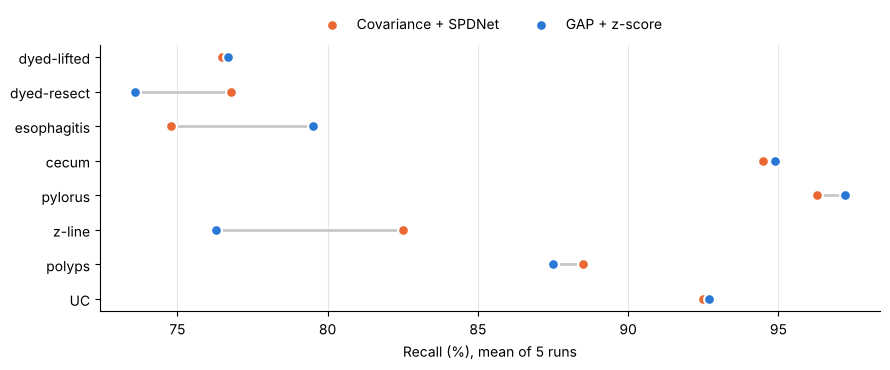

In [6]:
def recall(name):
    return pd.read_csv(os.path.join(RES, name, 'per_class.csv'), sep=';').set_index('class')['recall_mean'] * 100

rec = pd.DataFrame({'Covariance + SPDNet': recall('kvasir_spdnet'), 'GAP + z-score': recall('kvasir_gap_zscore')})
rec['SPDNet − GAP'] = rec.iloc[:, 0] - rec.iloc[:, 1]
display(rec)

fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(rec))[::-1]
ax.hlines(y, rec.iloc[:, 0], rec.iloc[:, 1], color='#c8c8c8', lw=2, zorder=1)
ax.scatter(rec.iloc[:, 0], y, s=60, color=SPD, label='Covariance + SPDNet', zorder=2, edgecolor='white', linewidth=1.5)
ax.scatter(rec.iloc[:, 1], y, s=60, color=GAP, label='GAP + z-score', zorder=2, edgecolor='white', linewidth=1.5)
ax.set_yticks(y, rec.index)
ax.set_xlabel('Recall (%), mean of 5 runs')
ax.legend(frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='x', color='#e5e5e5')
ax.set_axisbelow(True)
fig.tight_layout()

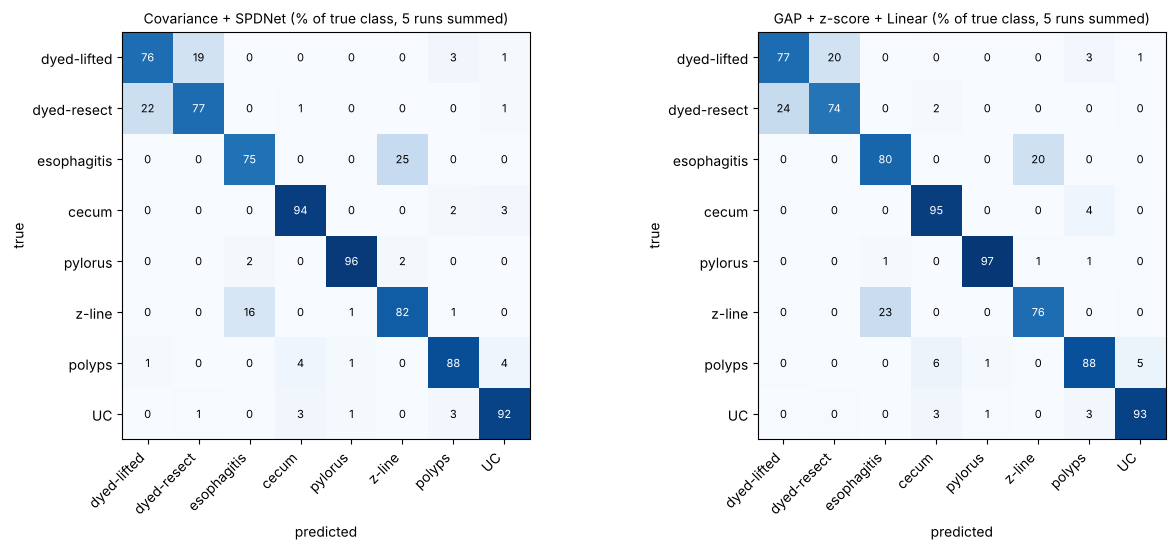

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
for ax, name in zip(axes, ('kvasir_spdnet', 'kvasir_gap_zscore')):
    cm = np.loadtxt(os.path.join(RES, name, 'confusion_matrix_sum.csv'), delimiter=';')
    cmn = cm / cm.sum(1, keepdims=True)
    classes = list(rec.index)
    ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, f'{100 * cmn[i, j]:.0f}', ha='center', va='center', fontsize=8,
                    color='white' if cmn[i, j] > 0.5 else 'black')
    ax.set_xticks(range(len(classes)), classes, rotation=45, ha='right')
    ax.set_yticks(range(len(classes)), classes)
    ax.set_xlabel('predicted'); ax.set_ylabel('true')
    ax.set_title(EXPERIMENTS[name][1] + ' (% of true class, 5 runs summed)', fontsize=10)
fig.tight_layout()

SPDNet gains on z-line and loses on esophagitis, so most of the per-class difference is the
decision boundary between the same two look-alike classes shifting, not a pair that is newly separated.

## 6. Cost

In [8]:
def minutes(n): return json.load(open(os.path.join(RES, n, 'fit_summary.json')))['minutes']
cost = pd.DataFrame({
    'MedSAM feature extraction': ['same for both (~0.5 s/image; Kvasir 67 min, Derma 72 min)'] * 2,
    'Stored per image': ['256 KB (256×256 float32)', '1 KB (256 float32)'],
    'Trainable params (Kvasir)': ['51,208', '2,056'],
    'Training, Kvasir (min)': [minutes('kvasir_spdnet'), minutes('kvasir_gap_zscore')],
    'Training, Derma (min)': [minutes('derma_spdnet'), minutes('derma_gap_zscore')],
}, index=['Covariance + SPDNet', 'GAP + z-score + Linear']).T
cost

,Covariance + SPDNet,GAP + z-score + Linear
MedSAM feature extraction,"same for both (~0.5 s/image; Kvasir 67 min, De...","same for both (~0.5 s/image; Kvasir 67 min, De..."
Stored per image,256 KB (256×256 float32),1 KB (256 float32)
Trainable params (Kvasir),"51,208","2,056"
"Training, Kvasir (min)",131.2,11.1
"Training, Derma (min)",176.0,4.9


SPDNet training is 12× (Kvasir) to 35× (Derma) slower: every batch needs eigendecompositions (ReEig, LogEig)
and the Riemannian optimiser. GPU: NVIDIA RTX 3050 Ti Laptop.

## 7. Why ReEig matters: MedSAM covariances have rank 255

`checks/phase1_checks.py` shows that the last LayerNorm2d of the MedSAM neck makes every pixel's 256 values
satisfy one linear constraint, so every covariance has an exact null direction, parallel to 1/γ of that layer.
The covariance is therefore only positive *semi*-definite; the ReEig layer (eigenvalues clipped at 1e-4) is
what keeps SPDNet's input valid.

In [9]:
lines = open(os.path.join(REPO, 'checks', 'outputs', 'phase1_checks.txt'), encoding='utf-8').read().splitlines()
start = next(i for i, l in enumerate(lines) if l.startswith('1.6'))
print('\n'.join(l for l in lines[start:start + 24] if l.strip() and not l.startswith('=')))

1.6  Is the MedSAM covariance SPD or only PSD?  (LayerNorm2d hypothesis)
neck[3].weight (gamma): min -0.0075  max 0.2402  any zero: False
Derma train[0]:
  smallest 5 eigenvalues : [8.237538108865874e-19, 4.542637894686175e-09, 7.128852704862983e-09, 2.726456609953988e-08, 4.3252258276975716e-08]
  largest  3 eigenvalues : [0.15823378239714994, 0.21090012176501632, 0.5180408684345752]
  ratio  lambda_1 / lambda_2 : 1.81e-10   (≈0 -> one exact null direction)
  numerical rank (tol 1e-10*max): 255 / 256
  |cos(eigvec_min, 1/gamma)|    : 1.000000  (1.0 = parallel)
  ||C v|| / ||C||               : 2.92e-11
  eigenvalues < 1e-4 (ReEig threshold): 59 / 256
  float32 smallest eigenvalue   : 4.024e-11
Kvasir:
  smallest 5 eigenvalues : [7.121059448349906e-19, 2.832041014059633e-09, 5.088297948998246e-09, 1.6471235241685282e-08, 2.5533330979838694e-08]
  largest  3 eigenvalues : [0.20933712720642644, 0.260935386565894, 0.4783821406916269]
  ratio  lambda_1 / lambda_2 : 2.51e-10   (≈0 -> one ex

## 8. Findings → answers to the four questions

**1. What does covariance keep that GAP loses?** How the 256 features vary *together* across the 4,096
patches (co-occurrence, spatial heterogeneity). It removes the mean first, and the mean is exactly GAP,
so the two descriptors hold complementary information rather than one containing the other.

**2. Why SPD / Riemannian learning?** Covariances live on the curved cone of SPD matrices; a plain linear
layer can break their structure. SPDNet keeps BiMap weights orthonormal (Stiefel manifold), repairs the
spectrum (ReEig, essential here because of rank 255) and maps to a flat space (LogEig) before a linear
classifier.

**3. Does the advantage hold on Kvasir-v2?** No. Against the z-score GAP baseline, balanced accuracy ties
on both datasets (Derma −1.5, Kvasir +0.5; both intervals include 0). The only significant gain, macro AUROC
on DermaMNIST (+1.3), disappears on Kvasir (+0.05). Possible reasons, not yet tested: 64² Derma images
upscaled to 1024² make patches nearly uniform, so co-occurrence adds a little; on sharp Kvasir images
the MedSAM means already separate the classes (AUROC ≈ 99).

**4. Trade-offs.** Same accuracy here, but 12–35× training time, 25× parameters and 256× storage per image.
Feature scaling of GAP mattered far more (+10 points) than the choice of head. A well-scaled GAP baseline is
the better default for MedSAM features; covariance pooling may still pay off with other encoders
(the paper reports much better SPDNet results with DINOv2).

**Limitations.** One encoder; one fixed split; Kvasir has no patient IDs; image size and on-screen overlays
correlate with class (possible shortcuts for both heads); default hyper-parameters from the official code.